# Alerts and liability triage

Flag the same EGFR subset with PAINS and BRENK (RDKit FilterCatalog, at runtime — those SMARTS are not vendored) and with the bundled NIBR 2019 deck filters. The question is not whether a set *can* fire, but how often it fires on known actives versus property-matched decoys, and whether that is useful as a hard filter or only as a flag.

In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw
from pharmprof.data import load_egfr
from pharmprof.alerts import flag_alerts, CATALOG_CITATIONS
from pharmprof.io import MolRecord

data = load_egfr(subset=True)
recs = [MolRecord(str(r.mol_id), r.smiles, Chem.MolFromSmiles(r.smiles), int(r.label)) for r in data.itertuples()]
alerts = flag_alerts(recs, catalogs=["PAINS", "BRENK", "NIBR"], n_jobs=4, progress=True)
alerts["label"] = [r.label for r in recs]
alerts.head()

/workspace/venvs/pharmprof/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


profile: 100%|██████████| 1/1 [00:16<00:00, 16.04s/chunk]


,mol_id,smiles,valid,n_filtercatalog_hits,filtercatalog_hits,n_nibr_hits,nibr_hits,n_nibr_exclude,n_alert_hits,any_alert,label
0,101343,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,True,1,Brenk:Polycyclic_aromatic_hydrocarbon_2,2,halogen_aromatic_count_3; polycyclic_systems_1...,0,3,True,1
1,81022,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,True,0,,1,halogen_aromatic_count_3,0,1,True,1
2,101370,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,True,0,,1,halogen_aromatic_count_3,0,1,True,1
3,290482,Cn1cnc2cc3ncnc(Nc4cccc(Br)c4)c3cc21,True,0,,1,halogen_aromatic_count_3,0,1,True,1
4,299120,CCOc1cc2ncc(C#N)c(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2...,True,1,Brenk:Michael_acceptor_1,3,amide_acyclic_count_2; aromatic_ether_count_5;...,0,4,True,1


In [2]:
def rates(frame, col):
    act = frame.loc[frame.label == 1, col]
    dec = frame.loc[frame.label == 0, col]
    if col == "any_alert":
        return float(act.mean()), float(dec.mean())
    return float((act > 0).mean()), float((dec > 0).mean())

rows = []
for col, name in [
    ("n_filtercatalog_hits", "PAINS or BRENK (any hit)"),
    ("n_nibr_hits", "NIBR 2019 (any hit)"),
    ("n_nibr_exclude", "NIBR 2019 EXCLUDE severity"),
    ("any_alert", "Any catalog"),
]:
    a, d = rates(alerts, col)
    rows.append({"flag": name, "actives": a, "decoys": d, "n_actives": int(((alerts.label==1) & (alerts[col] > 0 if col != "any_alert" else alerts[col])).sum()),
                 "n_decoys": int(((alerts.label==0) & (alerts[col] > 0 if col != "any_alert" else alerts[col])).sum())})
pd.DataFrame(rows)

,flag,actives,decoys,n_actives,n_decoys
0,PAINS or BRENK (any hit),0.494465,0.4120,268,1030
1,NIBR 2019 (any hit),0.974170,0.9804,528,2451
2,NIBR 2019 EXCLUDE severity,0.302583,0.5124,164,1281
3,Any catalog,0.977860,0.9836,530,2459


On this set the all-NIBR table is too sensitive to use as a hard discard (it flags ~97% of actives and ~98% of decoys). The EXCLUDE severity subset is stricter. PAINS + BRENK fire on about half the actives and 41% of the decoys — kinase anilines and related motifs are known to trip some of these rules — so treat them as triage annotations, not as a reason to throw the active set away. Citations used:

PAINS: Baell JB, Holloway GA. J Med Chem. 2010;53(7):2719-2740. doi:10.1021/jm901137j
BRENK: Brenk R, et al. ChemMedChem. 2008;3(3):435-444. doi:10.1002/cmdc.200700139
NIBR: Schuffenhauer A, et al. J Med Chem. 2020;63(23):14425-14447. doi:10.1021/acs.jmedchem.0c01332


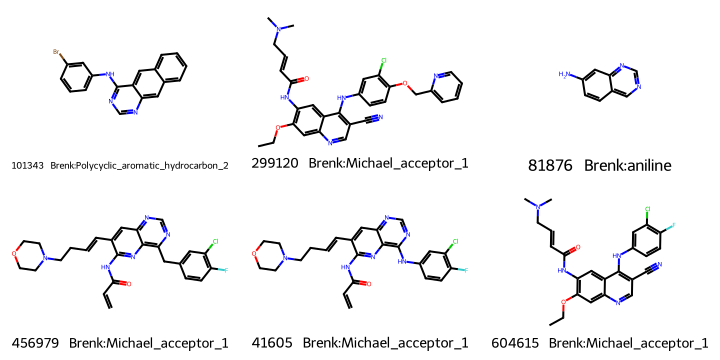

In [3]:
for name in ("PAINS", "BRENK", "NIBR"):
    print(f"{name}: {CATALOG_CITATIONS[name]}")

# A few actives that carry a PAINS/BRENK flag, for inspection
flagged = alerts[(alerts.label == 1) & (alerts.n_filtercatalog_hits > 0)].head(6)
mols = [Chem.MolFromSmiles(s) for s in flagged.smiles]
legends = [f"{i}  {h[:40]}" for i, h in zip(flagged.mol_id, flagged.filtercatalog_hits)]
Draw.MolsToGridImage(mols, legends=legends, molsPerRow=3, subImgSize=(240, 180))